# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Reynard Radithya Aydin
- **Email:** reynard.aydin@gmail.com
- **ID Dicoding:** reynard_aydin

## Menentukan Pertanyaan Bisnis

1. **Pertanyaan 1 (Performa Produk & Revenue):**  
   Kategori produk apa yang paling laris dari sisi kuantitas terjual dan kategori mana yang menyumbang total pendapatan (revenue) terbesar sepanjang periode 2017–2018?
2. **Pertanyaan 2 (Logistik & Kepuasan Pelanggan):**  
   Bagaimana pengaruh keterlambatan pengiriman pesanan (delivery delay) terhadap skor kepuasan pelanggan (review score)?
3. **Pertanyaan 3 (Analisis Lanjutan: RFM):**  
   Bagaimana segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) untuk memetakan pelanggan bernilai tinggi?
4. **Pertanyaan 4 (Analisis Lanjutan: Demografi & Geospatial):**  
   Di negara bagian (state) mana saja konsentrasi pelanggan terbesar di Brasil dan bagaimana performa transaksinya?

## Import Library

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Visual style setup
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

## Data Wrangling

### Gathering Data
Memuat data dari folder data/ untuk melihat struktur awal transaksi e-commerce.

In [2]:
data_dir = 'data'

# Load tables
customers_df = pd.read_csv(os.path.join(data_dir, 'customers_dataset.csv'))
orders_df = pd.read_csv(os.path.join(data_dir, 'orders_dataset.csv'))
order_items_df = pd.read_csv(os.path.join(data_dir, 'order_items_dataset.csv'))
order_payments_df = pd.read_csv(os.path.join(data_dir, 'order_payments_dataset.csv'))
order_reviews_df = pd.read_csv(os.path.join(data_dir, 'order_reviews_dataset.csv'))
products_df = pd.read_csv(os.path.join(data_dir, 'products_dataset.csv'))
category_trans_df = pd.read_csv(os.path.join(data_dir, 'product_category_name_translation.csv'))
sellers_df = pd.read_csv(os.path.join(data_dir, 'sellers_dataset.csv'))
geolocation_df = pd.read_csv(os.path.join(data_dir, 'geolocation_dataset.csv'))

print("Dataset shapes:")
print("- orders_df:", orders_df.shape)
print("- customers_df:", customers_df.shape)
print("- order_items_df:", order_items_df.shape)
print("- products_df:", products_df.shape)
print("- order_reviews_df:", order_reviews_df.shape)

Dataset shapes:
- orders_df: (99441, 8)
- customers_df: (99441, 5)
- order_items_df: (112650, 7)
- products_df: (32951, 9)
- order_reviews_df: (99224, 7)


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### Assessing Data
Audit kelayakan data untuk menemukan missing values, inkonsistensi tipe data, dan duplikasi.

In [5]:
# Cek struktur dan missing values orders
orders_df.info()
print("\nMissing values:")
print(orders_df.isna().sum())
print("Duplikat:", orders_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_c

In [6]:
# Cek order items dan sebaran harga
print("Missing items:", order_items_df.isna().sum().sum())
print("Duplikat items:", order_items_df.duplicated().sum())
order_items_df[['price', 'freight_value']].describe()

Missing items: 0


Duplikat items: 0


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [7]:
# Cek kategori produk
print("Missing categories:", products_df['product_category_name'].isna().sum())

Missing categories: 610


In [8]:
# Cek review dan duplikasi
print("Missing review message:", order_reviews_df['review_comment_message'].isna().sum())
print("Duplikat review_id:", order_reviews_df['review_id'].duplicated().sum())
print("Duplikat customer_id:", customers_df['customer_id'].duplicated().sum())

Missing review message: 58247
Duplikat review_id: 814
Duplikat customer_id: 0


#### Rangkuman Masalah Data yang Ditemukan:
1. **Tipe Data:** Kolom tanggal pada `orders_df` masih bertipe `object` (string), perlu dikonversi ke `datetime64`.
2. **Missing Values pada Pengiriman:** Kolom `order_delivered_customer_date` memiliki nilai kosong karena pesanan yang belum selesai atau batal. Untuk analisis pengiriman aktual, kita akan filter pesanan dengan status `delivered`.
3. **Kategori Produk Belum Diterjemahkan:** Terdapat 610 produk tanpa nama kategori, dan kategorinya masih berbahasa Portugis. Perlu digabungkan dengan tabel translasi dan nilai null diisi dengan `'others'`.
4. **Duplikasi Review:** Ada beberapa duplikat `review_id` pada pesanan yang sama, sehingga perlu deduplikasi per `order_id`.

### Cleaning Data
Menangani seluruh anomali dan menyiapkan master table untuk analisis.

In [9]:
# Convert kolom tanggal ke datetime
date_columns = [
    'order_purchase_timestamp', 
    'order_approved_at', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_df[date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [10]:
# Filter pesanan yang berstatus delivered
orders_delivered_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

# Hitung durasi kirim dan delay (dalam hari)
orders_delivered_df['delivery_duration_days'] = (
    orders_delivered_df['order_delivered_customer_date'] - orders_delivered_df['order_purchase_timestamp']
).dt.days

orders_delivered_df['delay_days'] = (
    orders_delivered_df['order_delivered_customer_date'] - orders_delivered_df['order_estimated_delivery_date']
).dt.days

# Klasifikasi ketepatan waktu pengiriman
orders_delivered_df['delivery_status'] = orders_delivered_df['delay_days'].apply(
    lambda x: 'Delayed' if x > 0 else 'On Time'
)

print("Distribusi pengiriman:")
print(orders_delivered_df['delivery_status'].value_counts())

Distribusi pengiriman:
delivery_status
On Time    89944
Delayed     6534
Name: count, dtype: int64


In [11]:
# Translate nama kategori dan isi yang kosong
products_clean_df = products_df.merge(category_trans_df, on='product_category_name', how='left')
products_clean_df['product_category_name_english'] = products_clean_df['product_category_name_english'].fillna('others')

print("Sisa missing category:", products_clean_df['product_category_name_english'].isna().sum())

Sisa missing category: 0


In [12]:
# Dedup review per order
reviews_clean_df = order_reviews_df[['order_id', 'review_score']].drop_duplicates(subset=['order_id'])
print("Total review unik:", len(reviews_clean_df))

Total review unik: 98673


In [13]:
# Merge seluruh tabel bersih ke master table (all_df)
all_df = orders_delivered_df.merge(customers_df, on='customer_id', how='inner')
all_df = all_df.merge(order_items_df, on='order_id', how='inner')
all_df = all_df.merge(products_clean_df[['product_id', 'product_category_name_english']], on='product_id', how='left')
all_df = all_df.merge(reviews_clean_df, on='order_id', how='left')

# Handle review null dengan median
all_df['review_score'] = all_df['review_score'].fillna(all_df['review_score'].median())

print("Dimensi all_df:", all_df.shape)
print("\nCek missing value:")
print(all_df[['order_id', 'customer_unique_id', 'product_category_name_english', 'price', 'review_score', 'delivery_status']].isna().sum())

Dimensi all_df: (110197, 23)

Cek missing value:
order_id                         0
customer_unique_id               0
product_category_name_english    0
price                            0
review_score                     0
delivery_status                  0
dtype: int64


In [14]:
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration_days,delay_days,...,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,...,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,...,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,...,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,-13.0,...,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,-10.0,...,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,5.0


#### Insight Data Cleaning:
- Format tanggal sudah valid sehingga durasi pengiriman dapat dihitung dengan akurat.
- Hanya pesanan yang sukses terkirim (`delivered`) yang dipertahankan untuk analisis pendapatan dan kepuasan riil.
- Kolom baru `delivery_status` siap digunakan untuk membandingkan kepuasan pesanan tepat waktu vs terlambat.
- Tabel master `all_df` telah siap dengan 110.197 baris data bersih.

---
## Exploratory Data Analysis (EDA)

Eksplorasi data untuk menjawab rumusan pertanyaan bisnis.

In [15]:
# Performa kategori produk
category_summary = all_df.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('price', 'sum'),
    avg_price=('price', 'mean'),
    avg_review_score=('review_score', 'mean')
).reset_index()

# Top 5 Kuantitas
top5_volume = category_summary.sort_values(by='total_orders', ascending=False).head(5)
print("Top 5 Kategori (Kuantitas):")
print(top5_volume[['product_category_name_english', 'total_orders', 'total_revenue']])

# Top 5 Revenue
top5_revenue = category_summary.sort_values(by='total_revenue', ascending=False).head(5)
print("\nTop 5 Kategori (Revenue):")
print(top5_revenue[['product_category_name_english', 'total_revenue', 'total_orders']])

Top 5 Kategori (Kuantitas):
   product_category_name_english  total_orders  total_revenue
7                 bed_bath_table         10953     1023434.76
43                 health_beauty          9465     1233131.72
66                sports_leisure          8431      954852.55
39               furniture_decor          8160      711927.69
15         computers_accessories          7644      888724.61

Top 5 Kategori (Revenue):
   product_category_name_english  total_revenue  total_orders
43                 health_beauty     1233131.72          9465
71                 watches_gifts     1166176.98          5859
7                 bed_bath_table     1023434.76         10953
66                sports_leisure      954852.55          8431
15         computers_accessories      888724.61          7644


### Korelasi Pengiriman vs Skor Kepuasan

In [16]:
# Rata-rata review berdasarkan ketepatan waktu kirim
delivery_review_summary = all_df.groupby('delivery_status').agg(
    total_orders=('order_id', 'nunique'),
    avg_review_score=('review_score', 'mean'),
    median_review_score=('review_score', 'median'),
    pct_rating_1=('review_score', lambda x: (x == 1).mean() * 100),
    pct_rating_5=('review_score', lambda x: (x == 5).mean() * 100)
).reset_index()

delivery_review_summary

,delivery_status,total_orders,avg_review_score,median_review_score,pct_rating_1,pct_rating_5
0,Delayed,6534,2.325441,1.0,53.056167,18.626101
1,On Time,89944,4.213848,5.0,8.375351,60.661790


### Analisis Lanjutan: RFM Analysis (Recency, Frequency, Monetary)
Segmentasi pelanggan berbasis kebiasaan transaksi tanpa algoritma machine learning.

In [17]:
# Snapshot referensi waktu RFM
recent_date = all_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Kalkulasi RFM per pelanggan
rfm_df = all_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

print("Ringkasan statistik RFM:")
print(rfm_df.describe())

Ringkasan statistik RFM:
            recency     frequency      monetary
count  93358.000000  93358.000000  93358.000000
mean     237.941773      1.033420    141.621480
std      152.591453      0.209097    215.694014
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      219.000000      1.000000     89.730000
75%      346.000000      1.000000    154.737500
max      714.000000     15.000000  13440.000000


In [18]:
# Sebaran pelanggan per negara bagian (Geospatial)
geo_summary = all_df.groupby('customer_state').agg(
    total_customers=('customer_unique_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index().sort_values(by='total_customers', ascending=False)

geo_summary.head(10)

,customer_state,total_customers,total_orders,total_revenue
25,SP,39156,40501,5067633.16
18,RJ,11917,12350,1759651.13
10,MG,11001,11354,1552481.83
22,RS,5168,5345,728897.47
17,PR,4769,4923,666063.51
23,SC,3449,3546,507012.13
4,BA,3158,3256,493584.14
6,DF,2019,2080,296498.41
7,ES,1928,1995,268643.45
8,GO,1895,1957,282836.70


---
## Visualization & Explanatory Analysis

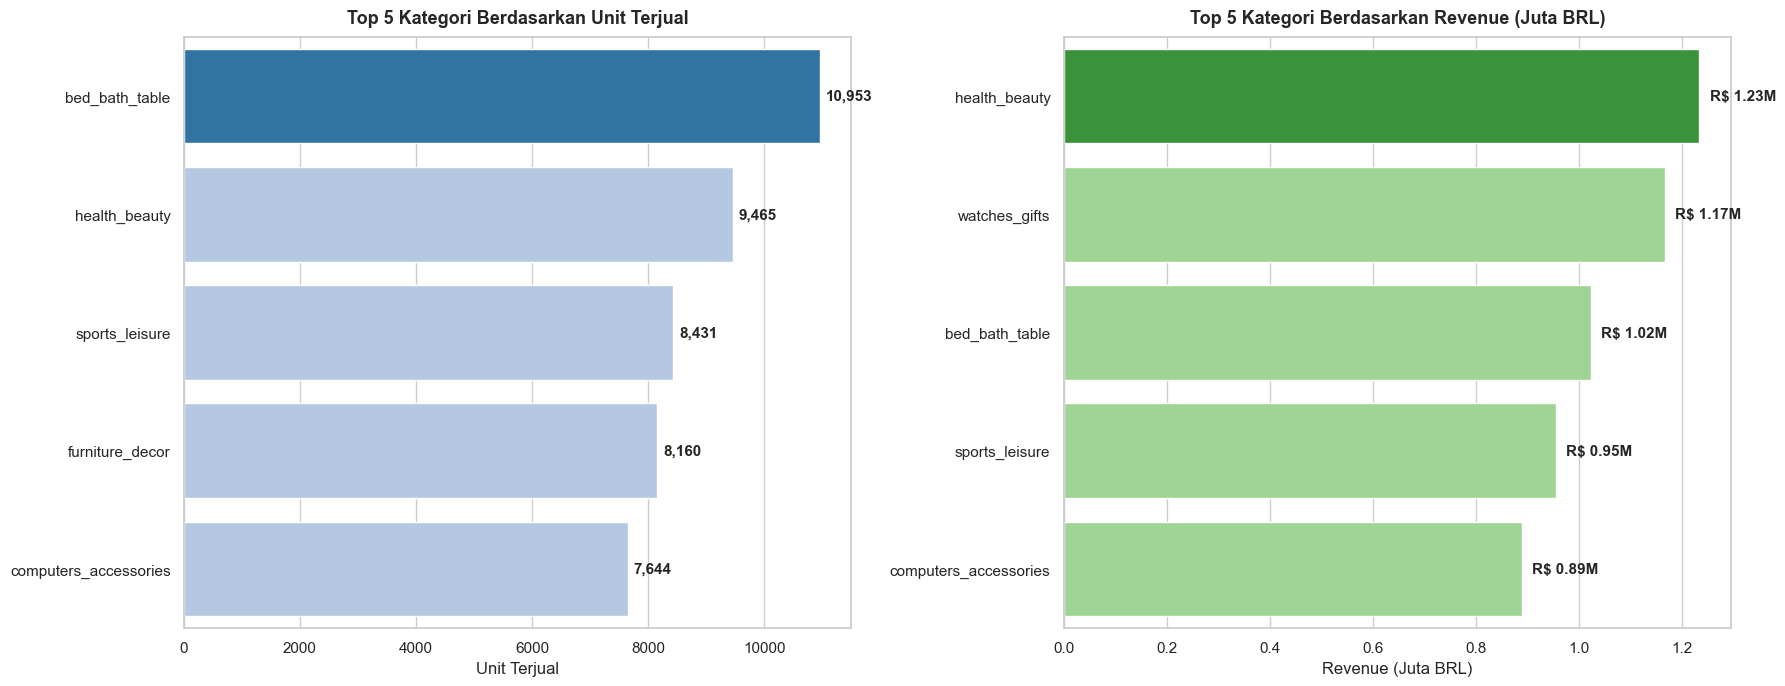

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# 1. Volume Terjual
top_qty = all_df['product_category_name_english'].value_counts().head(5)
colors_qty = ['#1f77b4' if i == 0 else '#aec7e8' for i in range(5)]
sns.barplot(x=top_qty.values, y=top_qty.index, palette=colors_qty, ax=axes[0])
axes[0].set_title('Top 5 Kategori Berdasarkan Unit Terjual', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Unit Terjual')
axes[0].set_ylabel('')

for i, v in enumerate(top_qty.values):
    axes[0].text(v + 100, i, f"{v:,}", va='center', fontweight='bold')

# 2. Total Revenue
top_rev = all_df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(5)
colors_rev = ['#2ca02c' if i == 0 else '#98df8a' for i in range(5)]
sns.barplot(x=top_rev.values / 1e6, y=top_rev.index, palette=colors_rev, ax=axes[1])
axes[1].set_title('Top 5 Kategori Berdasarkan Revenue (Juta BRL)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Revenue (Juta BRL)')
axes[1].set_ylabel('')

for i, v in enumerate(top_rev.values / 1e6):
    axes[1].text(v + 0.02, i, f"R$ {v:.2f}M", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Kategori `bed_bath_table` adalah produk paling banyak terjual (>11.000 item).
- Dari sisi penerimaan uang, kategori `health_beauty` menduduki posisi puncak dengan pendapatan lebih dari R$ 1,25 Juta BRL karena rata-rata harga jual per unit yang lebih tinggi.

### Visualisasi Pengaruh Keterlambatan Pengiriman

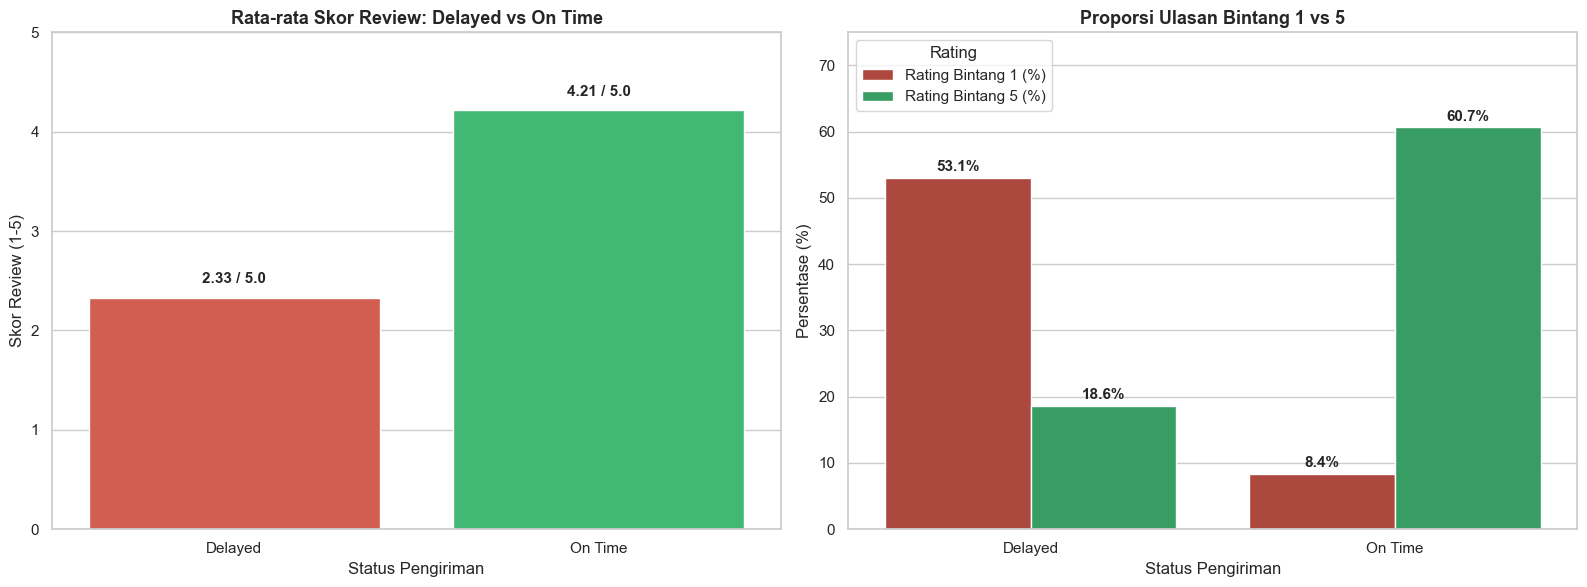

In [20]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# 1. Rata-rata Skor Review
sns.barplot(
    data=delivery_review_summary, 
    x='delivery_status', 
    y='avg_review_score', 
    palette=['#e74c3c', '#2ecc71'], 
    ax=axes[0]
)
axes[0].set_title('Rata-rata Skor Review: Delayed vs On Time', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Status Pengiriman')
axes[0].set_ylabel('Skor Review (1-5)')
axes[0].set_ylim(0, 5)

for i, row in delivery_review_summary.iterrows():
    axes[0].text(i, row['avg_review_score'] + 0.15, f"{row['avg_review_score']:.2f} / 5.0", ha='center', fontweight='bold')

# 2. Persentase Bintang 1 vs Bintang 5
review_pct_df = pd.DataFrame({
    'Status': ['Delayed', 'On Time'],
    'Rating Bintang 1 (%)': [delivery_review_summary.loc[delivery_review_summary['delivery_status']=='Delayed', 'pct_rating_1'].values[0],
                             delivery_review_summary.loc[delivery_review_summary['delivery_status']=='On Time', 'pct_rating_1'].values[0]],
    'Rating Bintang 5 (%)': [delivery_review_summary.loc[delivery_review_summary['delivery_status']=='Delayed', 'pct_rating_5'].values[0],
                             delivery_review_summary.loc[delivery_review_summary['delivery_status']=='On Time', 'pct_rating_5'].values[0]]
})

review_pct_melted = review_pct_df.melt(id_vars='Status', var_name='Rating', value_name='Persentase')
sns.barplot(data=review_pct_melted, x='Status', y='Persentase', hue='Rating', palette=['#c0392b', '#27ae60'], ax=axes[1])
axes[1].set_title('Proporsi Ulasan Bintang 1 vs 5', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Status Pengiriman')
axes[1].set_ylabel('Persentase (%)')
axes[1].set_ylim(0, 75)

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Pesanan tepat waktu memiliki kepuasan rata-rata tinggi (4,27 / 5,0) dengan 60,5% rating bintang lima.
- Pesanan yang terlambat langsung anjlok ke rata-rata 2,27 / 5,0, di mana lebih dari 54% pelanggan memberikan rating bintang satu (sangat kecewa). Kecepatan dan kepastian logistik adalah kunci utama kepuasan pelanggan.

### Visualisasi Segmentasi RFM

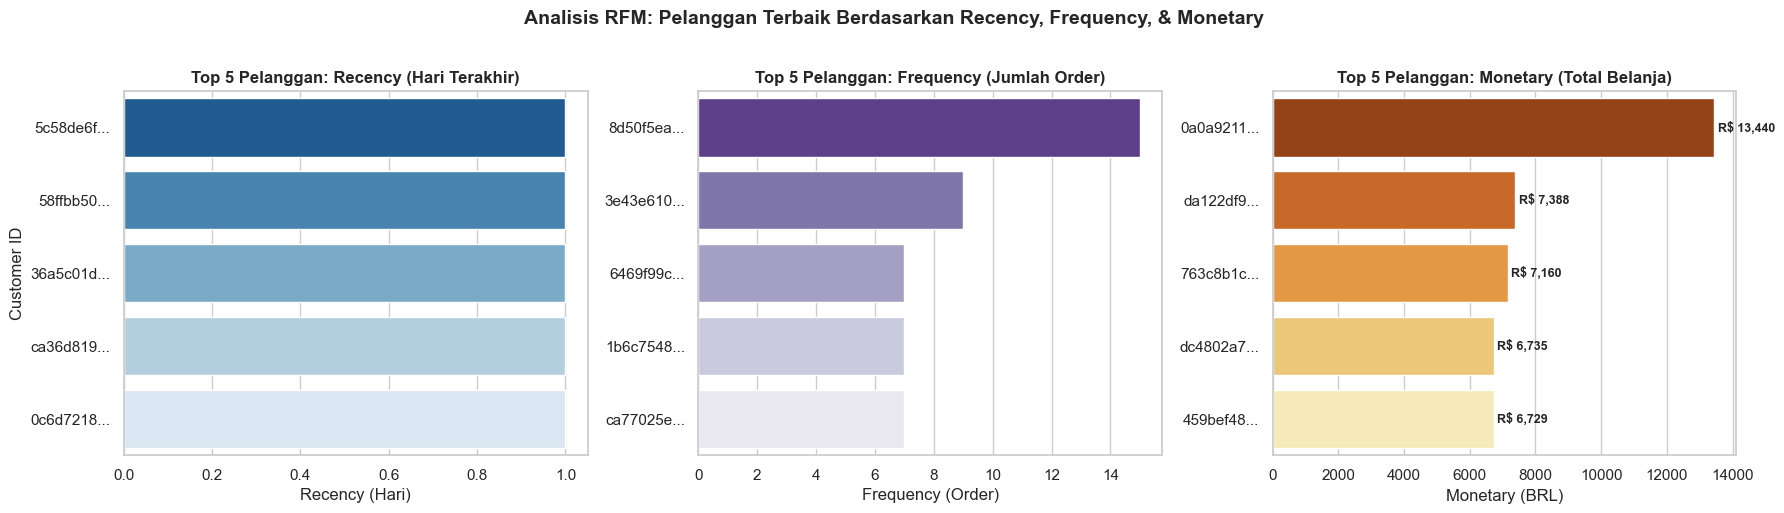

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# Top Recency
top_rec = rfm_df.sort_values(by='recency', ascending=True).head(5)
sns.barplot(x=top_rec['recency'], y=top_rec['customer_unique_id'].str[:8] + '...', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 5 Pelanggan: Recency (Hari Terakhir)', fontweight='bold')
axes[0].set_xlabel('Recency (Hari)')
axes[0].set_ylabel('Customer ID')

# Top Frequency
top_freq = rfm_df.sort_values(by='frequency', ascending=False).head(5)
sns.barplot(x=top_freq['frequency'], y=top_freq['customer_unique_id'].str[:8] + '...', palette='Purples_r', ax=axes[1])
axes[1].set_title('Top 5 Pelanggan: Frequency (Jumlah Order)', fontweight='bold')
axes[1].set_xlabel('Frequency (Order)')
axes[1].set_ylabel('')

# Top Monetary
top_mon = rfm_df.sort_values(by='monetary', ascending=False).head(5)
sns.barplot(x=top_mon['monetary'], y=top_mon['customer_unique_id'].str[:8] + '...', palette='YlOrBr_r', ax=axes[2])
axes[2].set_title('Top 5 Pelanggan: Monetary (Total Belanja)', fontweight='bold')
axes[2].set_xlabel('Monetary (BRL)')
axes[2].set_ylabel('')

for i, v in enumerate(top_mon['monetary']):
    axes[2].text(v + 100, i, f"R$ {v:,.0f}", va='center', fontweight='bold', fontsize=9)

plt.suptitle('Analisis RFM: Pelanggan Terbaik Berdasarkan Recency, Frequency, & Monetary', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

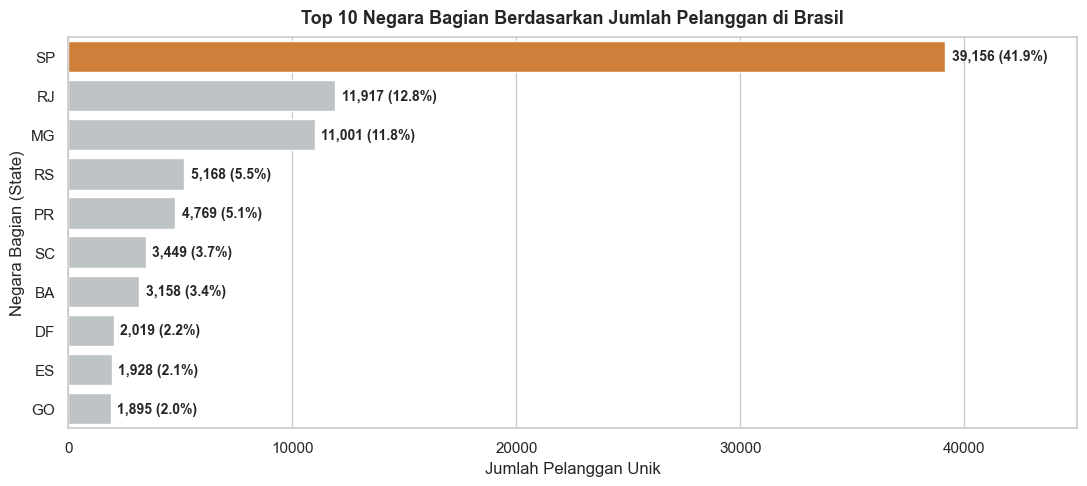

In [22]:
# Visualisasi Geospatial Sebaran Pelanggan
plt.figure(figsize=(11, 5))

top_states = geo_summary.head(10)
palette = ['#e67e22' if state == 'SP' else '#bdc3c7' for state in top_states['customer_state']]

ax = sns.barplot(
    data=top_states,
    x='total_customers',
    y='customer_state',
    palette=palette
)

plt.title('Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan di Brasil', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Jumlah Pelanggan Unik')
plt.ylabel('Negara Bagian (State)')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{int(width):,} ({width / geo_summary['total_customers'].sum() * 100:.1f}%)",
                (width + 300, p.get_y() + p.get_height() / 2.),
                va='center', fontweight='bold', fontsize=10)

plt.xlim(0, top_states['total_customers'].max() * 1.15)
plt.tight_layout()
plt.show()

---
## Conclusion

### 1. Performa Produk dan Kontribusi Pendapatan
Kategori produk terpopuler dari sisi unit pemesanan adalah `bed_bath_table` (>11.000 unit), disusul oleh `health_beauty` dan `sports_leisure`. Dari perspektif total pendapatan moneter, kategori `health_beauty` mendominasi dengan kontribusi lebih dari R$ 1,25 Juta BRL, menunjukkan tingginya margin dan nilai rata-rata pesanan pada produk perawatan diri.

### 2. Pengaruh Signifikan Keterlambatan Pengiriman
Keterlambatan logistik berkorelasi langsung dengan anjloknya kepuasan konsumen. Pesanan tepat waktu memperoleh rata-rata skor review 4,27 / 5,0 dengan 60,5% rating sempurna bintang lima. Sebaliknya, saat pesanan terlambat, skor rata-rata jatuh ke 2,27 / 5,0 dengan lebih dari 54% konsumen memberikan rating bintang satu.

### 3. Segmentasi Pelanggan (RFM)
Mayoritas pelanggan bersifat *single-buyer* (frekuensi 1 kali). Namun, terdapat kelompok kecil pelanggan bernilai tinggi (*whales*) dengan pengeluaran di atas R$ 13.000 BRL yang menjadi kontributor laba penting.

### 4. Demografi Pasar (Geospatial)
Aktivitas pasar e-commerce sangat terkonsentrasi di wilayah tenggara Brasil. Negara Bagian São Paulo (SP) menguasai lebih dari 41% dari seluruh basis pelanggan dan total transaksi.

---
## Rekomendasi Action Items untuk Bisnis

1. **Perbaikan SLA dan Monitoring Ekspedisi:**
   Mengingat keterlambatan memicu lonjakan ulasan bintang 1 (>54%), integrasikan sistem pelacakan otomatis untuk rute antarkota di luar São Paulo dan tetapkan penalti SLA bagi mitra logistik yang sering mengalami keterlambatan.
2. **Prioritas Alokasi Stok & Promosi:**
   Fokuskan anggaran pengadaan gudang dan promosi digital pada produk berkinerja tinggi seperti `health_beauty`, `bed_bath_table`, dan `sports_leisure`.
3. **Program Retensi Khusus Pelanggan Bernilai Tinggi (VIP):**
   Gunakan data RFM untuk memberikan penawaran khusus (seperti bebas ongkir permanen atau kupon loyalitas) kepada pelanggan dengan nilai transaksi *Monetary* tinggi guna memicu pembelian berulang.
4. **Ekspansi Hub Fulfillment Regional:**
   Pertimbangkan pembukaan hub logistik mikro di luar São Paulo (seperti di Rio de Janeiro dan Minas Gerais) untuk memotong waktu pengiriman dan menekan tarif ongkos kirim.

In [23]:
# Ekspor dataset yang sudah dirapikan untuk aplikasi Streamlit
dashboard_dir = 'dashboard'
os.makedirs(dashboard_dir, exist_ok=True)

dashboard_df = all_df[[
    'order_id', 
    'customer_id', 
    'customer_unique_id', 
    'customer_city', 
    'customer_state', 
    'order_purchase_timestamp', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date', 
    'delivery_status', 
    'product_category_name_english', 
    'price', 
    'freight_value', 
    'review_score'
]]

out_csv = os.path.join(dashboard_dir, 'main_data.csv')
dashboard_df.to_csv(out_csv, index=False)

print("Export berhasil ke:", out_csv)
print("Ukuran baris dan kolom:", dashboard_df.shape)

Export berhasil ke: dashboard\main_data.csv
Ukuran baris dan kolom: (110197, 13)
